# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

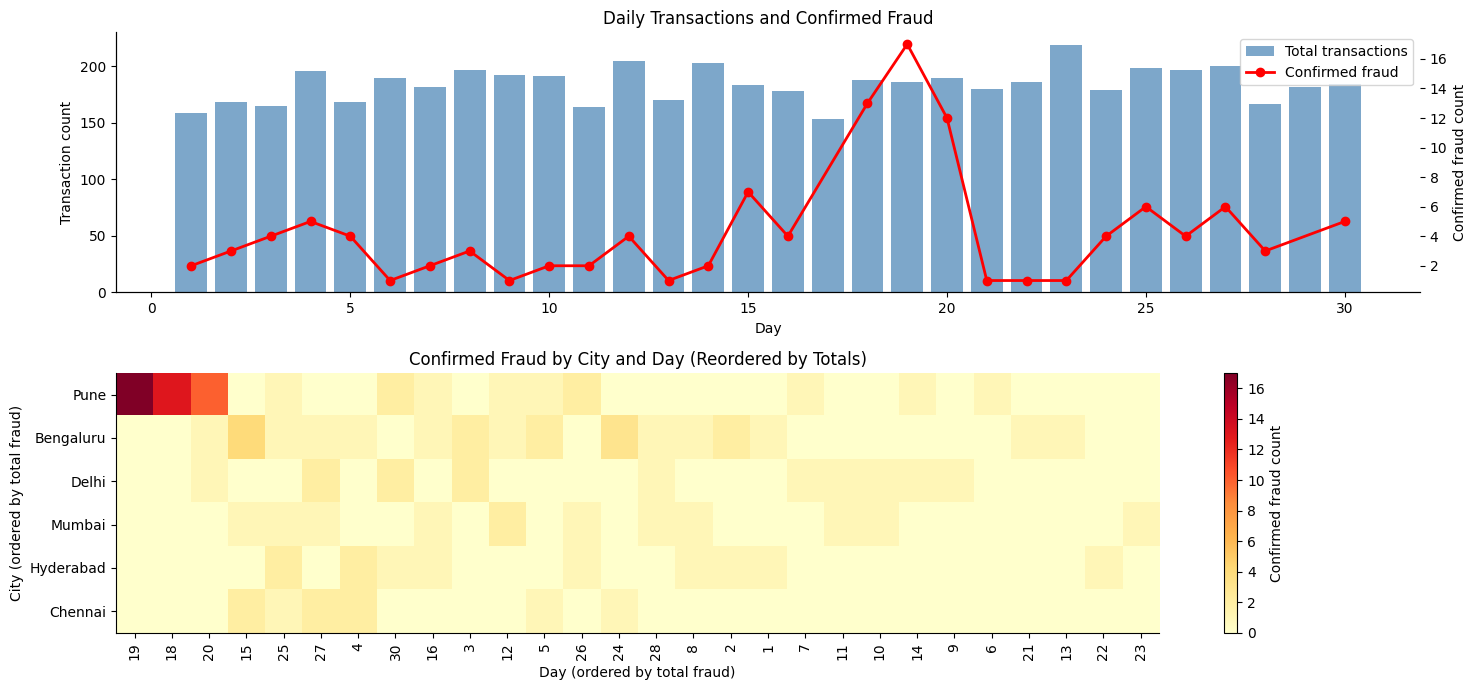

Top city-day cells by confirmed fraud:
     city  day  fraud_count
     Pune   19           17
     Pune   18           13
     Pune   20           10
Bengaluru   15            4
Bengaluru   24            3
Bengaluru    3            2
     Pune   26            2
Bengaluru    5            2
Hyderabad   25            2
Hyderabad    4            2


In [2]:

fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily transaction counts and confirmed fraud on a second axis
daily_tx = tx.groupby("day").size()
daily_fraud = tx[tx["is_fraud"] == 1].groupby("day").size()

axes[0].bar(daily_tx.index, daily_tx.values, color="steelblue", alpha=0.7,
            label="Total transactions")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Transaction count")
axes[0].set_title("Daily Transactions and Confirmed Fraud")

ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color="red",
         marker="o", linewidth=2, label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud count")

# Combine legends from both axes
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc="upper right")


# TODO 2: City × day confirmed-fraud matrix, reordered by totals
fraud_tx = tx[tx["is_fraud"] == 1]

heat = fraud_tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)

# Sort cities and days by their total confirmed fraud
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(heat, aspect="auto", cmap="YlOrRd")

axes[1].set_title("Confirmed Fraud by City and Day (Reordered by Totals)")
axes[1].set_xlabel("Day (ordered by total fraud)")
axes[1].set_ylabel("City (ordered by total fraud)")

axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns, rotation=90)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)

fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout()
plt.show()


# TODO 3: Print the city-day cells with the most fraud
top_cells = (
    heat.stack()
    .rename("fraud_count")
    .reset_index()
    .sort_values("fraud_count", ascending=False)
)

print("Top city-day cells by confirmed fraud:")
print(top_cells.head(10).to_string(index=False))


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

The overview showed daily fraud spikes and city-wise patterns that a score-sorted alert list might miss. This uses matrix reordering (Slide 39) to reveal patterns.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

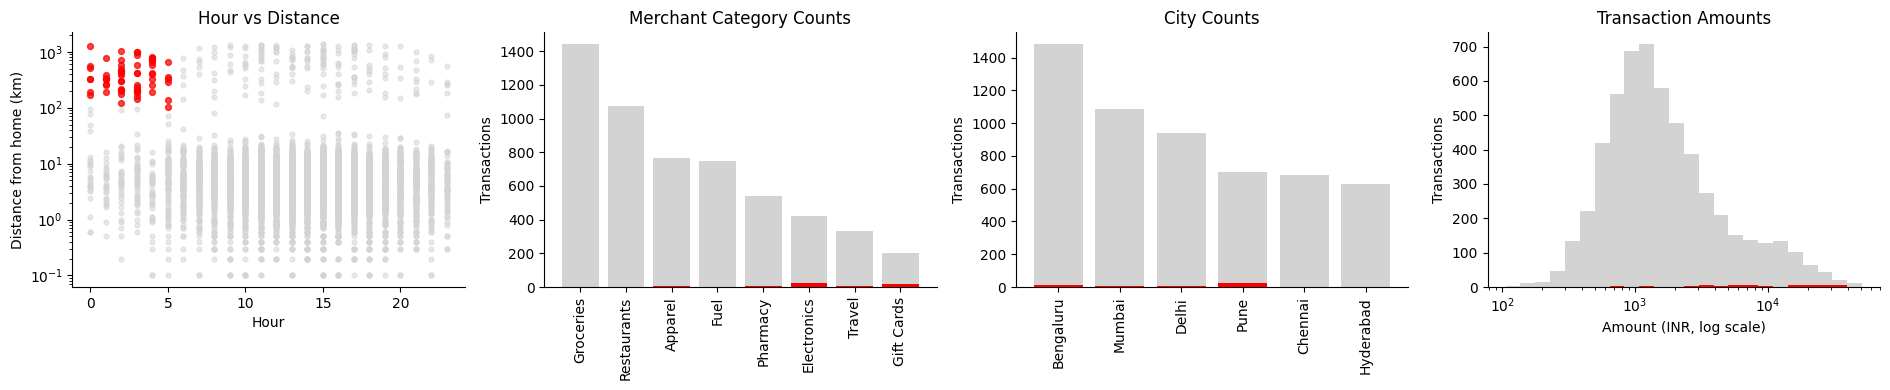

Transactions in brush: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured: 44.17%


In [3]:

# TODO 1: Define the brush
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)

all_tx = tx
brushed = tx[brush]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs distance scatter (log y-axis)
axes[0].scatter(
    all_tx["hour"], all_tx["distance_from_home_km"],
    color="lightgrey", alpha=0.5, s=12
)
axes[0].scatter(
    brushed["hour"], brushed["distance_from_home_km"],
    color="red", alpha=0.7, s=18
)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")

# TODO 2(b): Merchant category counts
categories = all_tx["merchant_category"].value_counts().index
all_counts = all_tx["merchant_category"].value_counts().reindex(categories, fill_value=0)
brush_counts = brushed["merchant_category"].value_counts().reindex(categories, fill_value=0)

axes[1].bar(categories, all_counts, color="lightgrey", label="All")
axes[1].bar(categories, brush_counts, color="red", label="Brushed")
axes[1].set_title("Merchant Category Counts")
axes[1].set_ylabel("Transactions")
axes[1].tick_params(axis="x", rotation=90)

# TODO 2(c): City counts
cities = all_tx["city"].value_counts().index
all_city_counts = all_tx["city"].value_counts().reindex(cities, fill_value=0)
brush_city_counts = brushed["city"].value_counts().reindex(cities, fill_value=0)

axes[2].bar(cities, all_city_counts, color="lightgrey")
axes[2].bar(cities, brush_city_counts, color="red")
axes[2].set_title("City Counts")
axes[2].set_ylabel("Transactions")
axes[2].tick_params(axis="x", rotation=90)

# TODO 2(d): Amount histogram (log10)
all_amounts = all_tx["amount_inr"].dropna()
brush_amounts = brushed["amount_inr"].dropna()

bins = np.logspace(
    np.log10(all_amounts.min()),
    np.log10(all_amounts.max()),
    25
)

axes[3].hist(all_amounts, bins=bins, color="lightgrey", label="All")
axes[3].hist(brush_amounts, bins=bins, color="red", label="Brushed")
axes[3].set_xscale("log")
axes[3].set_title("Transaction Amounts")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Transactions")

plt.tight_layout()
plt.show()


# TODO 3: Brush statistics
n_brushed = len(brushed)
fraud_in_brush = brushed["is_fraud"].sum()
total_fraud = tx["is_fraud"].sum()

brush_fraud_rate = fraud_in_brush / n_brushed if n_brushed else 0
overall_fraud_rate = tx["is_fraud"].mean()
fraud_capture_share = fraud_in_brush / total_fraud if total_fraud else 0

print(f"Transactions in brush: {n_brushed}")
print(f"Fraud rate inside brush: {brush_fraud_rate:.2%}")
print(f"Overall fraud rate: {overall_fraud_rate:.2%}")
print(f"Share of all fraud captured: {fraud_capture_share:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

The rule may have a high fraud rate but capture only a small share of all fraud, so investigators shouldn't rely on it alone. The merchant category and city views can hint at where other fraud occurs.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure the best of 5 filter runs
times = []

for _ in range(5):
    start = time.perf_counter()
    result = big.loc[
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    ]
    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1_000_000
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate for 50 million rows
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> "
      f"{per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip "
      f"{skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 20.0 ms -> 0.0199 us/row -> max 5,026,668 rows in 0.1 s
50M rows -> 0.99 s; must skip 89.9% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

Use pre-aggregation to filter summarized data instead of all 50M rows. The analyst would lose transaction-level detail.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

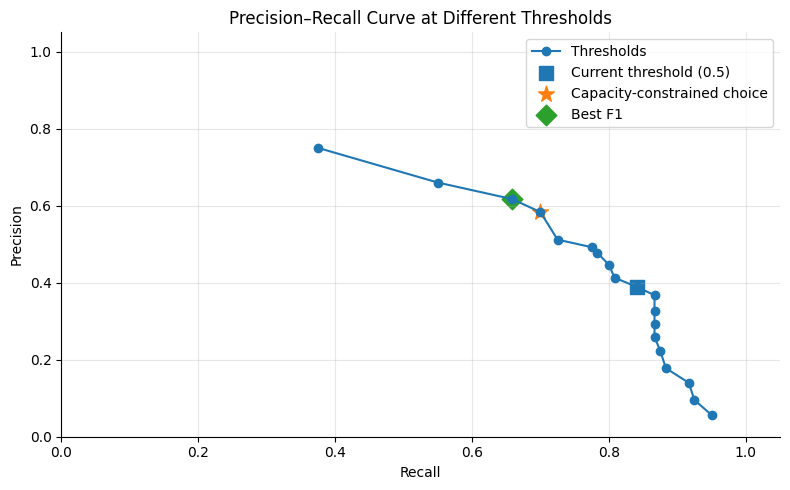

Recommendation: use threshold 0.80 (144 alerts, 70.0% recall) to stay within capacity; best-F1 threshold is 0.85 (F1=0.637).


In [5]:

rows = []

# TODO 1: Compute metrics for thresholds 0.05 to 0.95
y_true = tx["is_fraud"].astype(int)
scores = tx["detector_score"]

for threshold in np.arange(0.05, 1.00, 0.05):
    predicted = (scores >= threshold).astype(int)

    alerts = int(predicted.sum())
    TP = int(((predicted == 1) & (y_true == 1)).sum())
    FP = int(((predicted == 1) & (y_true == 0)).sum())
    FN = int(((predicted == 0) & (y_true == 1)).sum())

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "threshold": round(threshold, 2),
        "alerts": alerts,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)


# TODO 2: Capacity-constrained choice and best-F1 choice
eligible = pr[pr["alerts"] <= 150]

if eligible.empty:
    capacity_choice = None
    print("No tested threshold meets the 150-alert capacity.")
else:
    capacity_choice = eligible.sort_values(
        ["recall", "threshold"],
        ascending=[False, False]
    ).iloc[0]

best_f1 = pr.sort_values(
    ["F1", "threshold"],
    ascending=[False, False]
).iloc[0]


# TODO 3: Precision–recall curve and selected thresholds
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(pr["recall"], pr["precision"], marker="o",
        label="Thresholds")

current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]

ax.scatter(current["recall"], current["precision"],
           s=110, marker="s", label="Current threshold (0.5)")

if capacity_choice is not None:
    ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
               s=140, marker="*", label="Capacity-constrained choice")

ax.scatter(best_f1["recall"], best_f1["precision"],
           s=110, marker="D", label="Best F1")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve at Different Thresholds")
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# TODO 4: One-line recommendation
if capacity_choice is not None:
    print(
        f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
        f"({int(capacity_choice['alerts'])} alerts, "
        f"{capacity_choice['recall']:.1%} recall) to stay within capacity; "
        f"best-F1 threshold is {best_f1['threshold']:.2f} "
        f"(F1={best_f1['F1']:.3f})."
    )


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

The Head of Fraud Ops should make the final call because they understand the team's review capacity and the risks of missing fraud. Visual analytics keeps a human in the loop so the model supports decisions rather than making them alone (Slides 35–37).

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

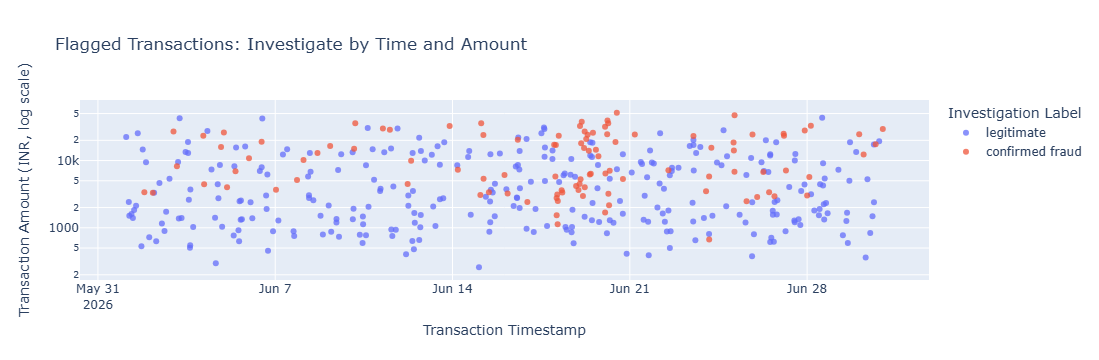

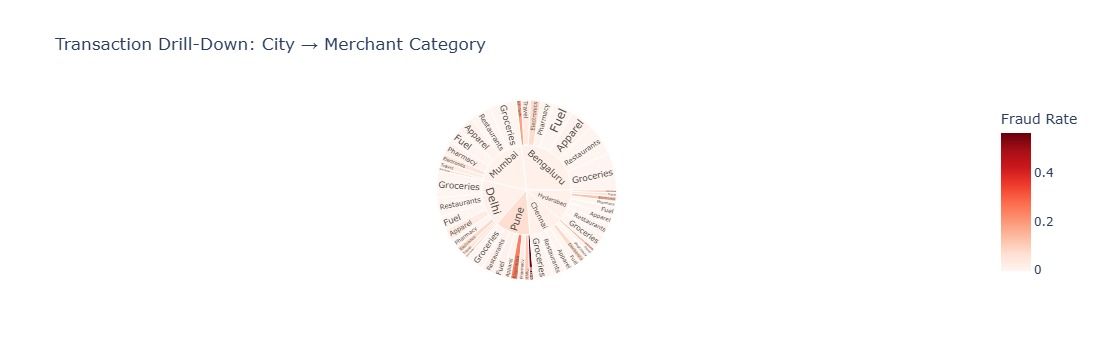

In [6]:

# TODO 1: Interactive scatter plot of flagged transactions
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": True,
        "detector_score": ":.4f",
        "timestamp": True,
        "amount_inr": ":.2f",
        "label": True
    },
    title="Flagged Transactions: Investigate by Time and Amount",
    labels={
        "timestamp": "Transaction Time",
        "amount_inr": "Amount (INR)",
        "label": "Investigation Label"
    },
    opacity=0.75
)

fig_scatter.update_layout(
    dragmode="select",
    xaxis_title="Transaction Timestamp",
    yaxis_title="Transaction Amount (INR, log scale)"
)

fig_scatter.show()


# TODO 2: Sunburst — city → merchant category
sunburst_data = (
    tx.groupby(["city", "merchant_category"], observed=True)
    .agg(
        transaction_count=("txn_id", "count"),
        fraud_count=("is_fraud", "sum")
    )
    .reset_index()
)

sunburst_data["fraud_rate"] = (
    sunburst_data["fraud_count"] / sunburst_data["transaction_count"]
)

fig_sunburst = px.sunburst(
    sunburst_data,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    hover_data={
        "transaction_count": True,
        "fraud_count": True,
        "fraud_rate": ":.2%"
    },
    title="Transaction Drill-Down: City → Merchant Category",
    labels={
        "transaction_count": "Transactions",
        "fraud_count": "Confirmed Fraud",
        "fraud_rate": "Fraud Rate"
    }
)

fig_sunburst.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

Hovering over 400 cases one by one is slow and makes patterns hard to spot. The scatter plot fixes this by showing all flagged cases together, letting investigators spot clusters and outliers quickly.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: Confirmed fraud is unusually concentrated in Pune on days 18-20.
Inside window: 107 transactions, 40 fraud, rate = 37.38%
Outside window: 5413 transactions, 80 fraud, rate = 1.48%
Chi-square p-value: 0.000000
Window: 107 transactions, 40 fraud, rate = 37.38%
Same city, other days: 593 transactions, 11 fraud, rate = 1.85%
Other cities, same days: 457 transactions, 2 fraud, rate = 0.44%
Rest: 4363 transactions, 67 fraud, rate = 1.54%


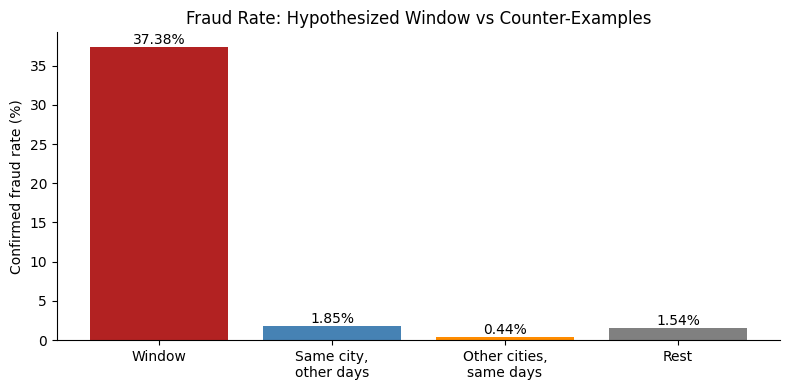

Verdict: The window has a statistically significant higher fraud rate. This supports further investigation, but does not prove a fraud ring.


In [7]:

from scipy.stats import chi2_contingency

# TODO 1: Define the hypothesis using the highest-fraud city-day cell
fraud_tx = tx[tx["is_fraud"] == 1]

city_day_counts = fraud_tx.groupby(["city", "day"]).size()
peak_city, peak_day = city_day_counts.idxmax()

# Start with a 3-day window around the peak day
start_day = max(1, peak_day - 1)
end_day = min(30, peak_day + 1)

in_city = tx["city"] == peak_city
in_days = tx["day"].between(start_day, end_day)

in_window = in_city & in_days

print(
    f"Hypothesis: Confirmed fraud is unusually concentrated in "
    f"{peak_city} on days {start_day}-{end_day}."
)


# TODO 2: Fraud rates inside vs outside and chi-square test
inside = tx[in_window]
outside = tx[~in_window]

inside_rate = inside["is_fraud"].mean()
outside_rate = outside["is_fraud"].mean()

contingency = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Inside window: {len(inside)} transactions, "
      f"{inside['is_fraud'].sum()} fraud, rate = {inside_rate:.2%}")
print(f"Outside window: {len(outside)} transactions, "
      f"{outside['is_fraud'].sum()} fraud, rate = {outside_rate:.2%}")
print(f"Chi-square p-value: {p_value:.6f}")


# TODO 3: Counter-example searches
same_city_other_days = in_city & ~in_days
other_cities_same_days = ~in_city & in_days
rest = ~in_city & ~in_days

groups = {
    "Window": in_window,
    "Same city,\nother days": same_city_other_days,
    "Other cities,\nsame days": other_cities_same_days,
    "Rest": rest
}

group_rates = {}
for name, mask in groups.items():
    subset = tx[mask]
    rate = subset["is_fraud"].mean() if len(subset) else 0
    group_rates[name] = rate
    print(f"{name.replace(chr(10), ' ')}: "
          f"{len(subset)} transactions, "
          f"{subset['is_fraud'].sum()} fraud, rate = {rate:.2%}")


# TODO 4: Visual confirmation
fig, ax = plt.subplots(figsize=(8, 4))

names = list(group_rates.keys())
rates = [group_rates[name] * 100 for name in names]

bars = ax.bar(names, rates, color=["firebrick", "steelblue",
                                  "darkorange", "grey"])

ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Fraud Rate: Hypothesized Window vs Counter-Examples")

for bar, rate in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{rate:.2f}%",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()


# TODO 5: Verdict
if p_value < 0.05 and inside_rate > outside_rate:
    print("Verdict: The window has a statistically significant higher fraud rate. "
          "This supports further investigation, but does not prove a fraud ring.")
else:
    print("Verdict: The evidence does not establish an unusually high fraud rate "
          "in this window. The fraud-ring hypothesis is not supported by this test.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

If other cities on the same days also had high fraud rates, it would weaken the hypothesis of a city-specific fraud ring and suggest a broader time-based fraud spike instead.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

Last month, PayKart recorded **5,520 transactions, including 120 confirmed fraud cases**. I recommend the threshold that maximizes recall while keeping alerts within the 150-case monthly capacity, balancing fraud detection with precision and investigator workload. The Head of Fraud Ops should make the final decision, keeping a human in the loop. Build the **interactive scatter plot** first, as it supports zooming, filtering and details-on-demand to help investigators explore flagged cases. Finally, add a **human feedback loop** where investigators' confirmed labels and corrections are used to evaluate and improve next month's detector.